# 21 — Interpretación del modelo final (SHAP) para la presentación

**SHAP** (no está en el material): para una predicción, reparte la diferencia entre la predicción de esa fila y la predicción "promedio" del modelo entre las features. Cada feature recibe un valor que dice cuánto empujó hacia `new` (positivo) o hacia `used` (negativo). Sumando todos los valores al valor base se obtiene exactamente la predicción del modelo, en escala log-odds. El promedio de |SHAP| sobre muchas filas da la **importancia global**.

- **CatBoost** (la mitad del modelo final): SHAP **nativo** de CatBoost (`get_feature_importance(type="ShapValues")`).
- **HistGB con combinaciones** (la otra mitad): SHAP con `shap.TreeExplainer` de la librería `shap`, sobre una muestra de 3.000 filas del fold 1 (el cálculo exacto para árboles es más lento que el nativo de CatBoost).

**Para que los ejemplos sean honestos:** los dos modelos se entrenan con los folds 2–5 y se explican filas del **fold 1**, que no vieron. Los gráficos se guardan en `notebooks/figuras/`.

In [1]:
import sys
sys.path.append("..")
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import Pool
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

from features import (aplanar_anidadas, agregar_features_contenido, agregar_categoricas_crudas, agregar_combos,
                      armar_pipeline_final, armar_pipeline_histgb_combos, COLUMNAS_NUMERICAS, COLUMNAS_CAT_CRUDAS,
                      COLUMNAS_COMBOS, INDICES_CAT)

SEED = 42
os.makedirs("figuras", exist_ok=True)
crudo = pd.read_json("../data/train_data.jsonlines", lines=True)
y = (crudo["condition"] == "new").astype(int)
train = agregar_combos(agregar_categoricas_crudas(agregar_features_contenido(aplanar_anidadas(crudo))))
entrena, valida = next(iter(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(train, y)))

inicio = time.time()
catboost, histgb = armar_pipeline_final(), armar_pipeline_histgb_combos()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    catboost.fit(train.iloc[entrena], y.iloc[entrena], modelo__cat_features=INDICES_CAT)
    histgb.fit(train.iloc[entrena], y.iloc[entrena])
X_val = train.iloc[valida]
y_val = y.iloc[valida].to_numpy()
prob_cat = catboost.predict_proba(X_val)[:, 1]
prob_hgb = histgb.predict_proba(X_val)[:, 1]
prob_final = 0.5 * prob_cat + 0.5 * prob_hgb
print(f"{(time.time() - inicio) / 60:.1f} min | accuracy fold 1 -> CatBoost {((prob_cat >= 0.5) == y_val).mean():.4f}, "
      f"HistGB {((prob_hgb >= 0.5) == y_val).mean():.4f}, promedio {((prob_final >= 0.5) == y_val).mean():.4f}")

1.2 min | accuracy fold 1 -> CatBoost 0.9415, HistGB 0.9428, promedio 0.9431


## Nombres de las features en la salida de cada pipeline

In [2]:
pre_cat = Pipeline(catboost.steps[:-1])
vocab_cat = pre_cat.named_steps["preprocesador"].named_transformers_["tfidf"].get_feature_names_out()
nombres_cat = (COLUMNAS_NUMERICAS + ["duracion_dias"] + [f"tfidf: {w}" for w in vocab_cat] + ["prob_texto_new"]
               + [c.replace("cat_", "") for c in COLUMNAS_CAT_CRUDAS])

pre_hgb = Pipeline(histgb.steps[:-1])
transf = pre_hgb.named_steps["preprocesador"].named_transformers_
nombres_hgb = (list(transf["onehot"].get_feature_names_out()) + COLUMNAS_NUMERICAS
               + [f"tfidf: {w}" for w in transf["tfidf"].get_feature_names_out()] + ["prob_texto_new"]
               + [f"TE {c}" for c in ["seller_id", "category_id"] + COLUMNAS_COMBOS]
               + ["seller_n_listings", "seller_avg_log_price", "duracion_dias"])

Xc_val = pre_cat.transform(X_val)
Xh_val = pre_hgb.transform(X_val)
assert Xc_val.shape[1] == len(nombres_cat) and Xh_val.shape[1] == len(nombres_hgb)
print("CatBoost:", Xc_val.shape, "| HistGB:", Xh_val.shape)

CatBoost: (14000, 532) | HistGB: (14000, 588)


## 1. SHAP de CatBoost: importancia global

Promedio de |SHAP| en las 14.000 filas del fold 1. Las 500 columnas del TF-IDF del título se agrupan en una sola barra ("TF-IDF título, 500 palabras"), sumando sus |SHAP|.

Chequeo (base + suma de SHAP = log-odds del modelo): True


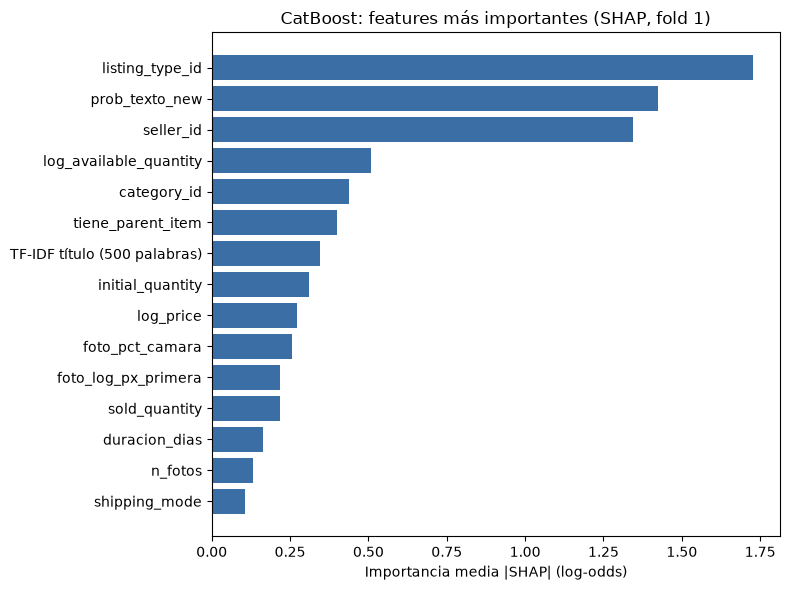

Palabras del TF-IDF con más |SHAP|: ['nuevo', 'de', 'el', 'estado', 'nueva', 'del', 'sin', 'hp', 'la', 'impecable']


listing_type_id                 1.7268
prob_texto_new                  1.4249
seller_id                       1.3453
log_available_quantity          0.5091
category_id                     0.4375
tiene_parent_item               0.3989
TF-IDF título (500 palabras)    0.3456
initial_quantity                0.3097
log_price                       0.2724
foto_pct_camara                 0.2548
foto_log_px_primera             0.2182
sold_quantity                   0.2170
duracion_dias                   0.1629
n_fotos                         0.1325
shipping_mode                   0.1058
dtype: float64

In [3]:
shap_cat = catboost.named_steps["modelo"].get_feature_importance(Pool(pd.DataFrame(Xc_val), cat_features=INDICES_CAT),
                                                                  type="ShapValues")
valor_base_cat = shap_cat[0, -1]
shap_cat = shap_cat[:, :-1]
chequeo = valor_base_cat + shap_cat.sum(axis=1)
print("Chequeo (base + suma de SHAP = log-odds del modelo):",
      np.allclose(1 / (1 + np.exp(-chequeo)), prob_cat, atol=1e-6))

importancia = pd.Series(np.abs(shap_cat).mean(axis=0), index=nombres_cat)
es_tfidf = importancia.index.str.startswith("tfidf: ")
agrupada = pd.concat([importancia[~es_tfidf],
                      pd.Series({"TF-IDF título (500 palabras)": np.abs(shap_cat[:, es_tfidf]).sum(axis=1).mean()})])
top = agrupada.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], color="#3b6ea5")
ax.set_xlabel("Importancia media |SHAP| (log-odds)")
ax.set_title("CatBoost: features más importantes (SHAP, fold 1)")
plt.tight_layout()
plt.savefig("figuras/shap_global_catboost.png", dpi=150)
plt.show()
print("Palabras del TF-IDF con más |SHAP|:", list(importancia[es_tfidf].sort_values(ascending=False).head(10).index.str.replace("tfidf: ", "")))
top.round(4)

## 2. SHAP del HistGB: importancia global

`shap.TreeExplainer` sobre 3.000 filas del fold 1 (muestra al azar, semilla 42). Mismo agrupamiento del TF-IDF en una sola barra.

/Users/nicolasscravaglieri/Downloads/kaggle-ap-2026/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP del HistGB: 0.0 min | forma (3000, 588)


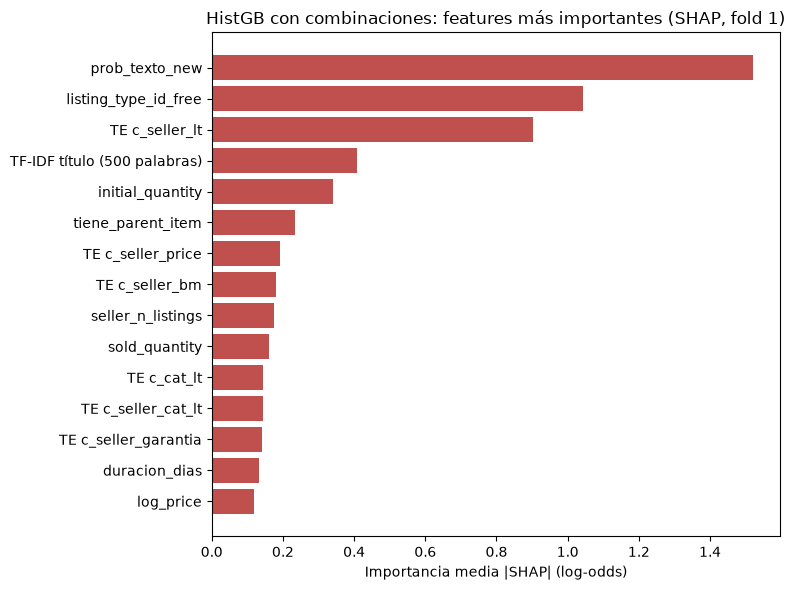

prob_texto_new                  1.5205
listing_type_id_free            1.0429
TE c_seller_lt                  0.9022
TF-IDF título (500 palabras)    0.4082
initial_quantity                0.3410
tiene_parent_item               0.2330
TE c_seller_price               0.1928
TE c_seller_bm                  0.1798
seller_n_listings               0.1736
sold_quantity                   0.1617
TE c_cat_lt                     0.1442
TE c_seller_cat_lt              0.1435
TE c_seller_garantia            0.1426
duracion_dias                   0.1319
log_price                       0.1189
dtype: float64

In [4]:
import shap

rng = np.random.default_rng(SEED)
muestra = rng.choice(len(Xh_val), size=3000, replace=False)
inicio = time.time()
explicador_hgb = shap.TreeExplainer(histgb.named_steps["modelo"])
shap_hgb = explicador_hgb.shap_values(Xh_val[muestra].astype(float))
shap_hgb = shap_hgb[1] if isinstance(shap_hgb, list) else shap_hgb
print(f"SHAP del HistGB: {(time.time() - inicio) / 60:.1f} min | forma {shap_hgb.shape}")

importancia_hgb = pd.Series(np.abs(shap_hgb).mean(axis=0), index=nombres_hgb)
es_tfidf_hgb = importancia_hgb.index.str.startswith("tfidf: ")
agrupada_hgb = pd.concat([importancia_hgb[~es_tfidf_hgb],
                          pd.Series({"TF-IDF título (500 palabras)": np.abs(shap_hgb[:, es_tfidf_hgb]).sum(axis=1).mean()})])
top_hgb = agrupada_hgb.sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_hgb.index[::-1], top_hgb.values[::-1], color="#c0504d")
ax.set_xlabel("Importancia media |SHAP| (log-odds)")
ax.set_title("HistGB con combinaciones: features más importantes (SHAP, fold 1)")
plt.tight_layout()
plt.savefig("figuras/shap_global_histgb.png", dpi=150)
plt.show()
top_hgb.round(4)

## 3. Ejemplos individuales (SHAP de CatBoost)

Tres publicaciones del fold 1:
1. un **acierto** con mucha seguridad;
2. un **error** con mucha seguridad;
3. una publicación que dura **60 días + unos segundos**, para ver el efecto de `duracion_dias`.

Cada gráfico muestra las 10 features que más empujaron la predicción (en log-odds; a la derecha, hacia `new`), con su valor, y el resto agrupado.

[acierto] Car-jgo Espirales Progresivo Traseros Volkswagen Gol Mod.199 | real new | P(new) 1.000 | duración 60.00000 días | vendedor con 405 publicaciones en train


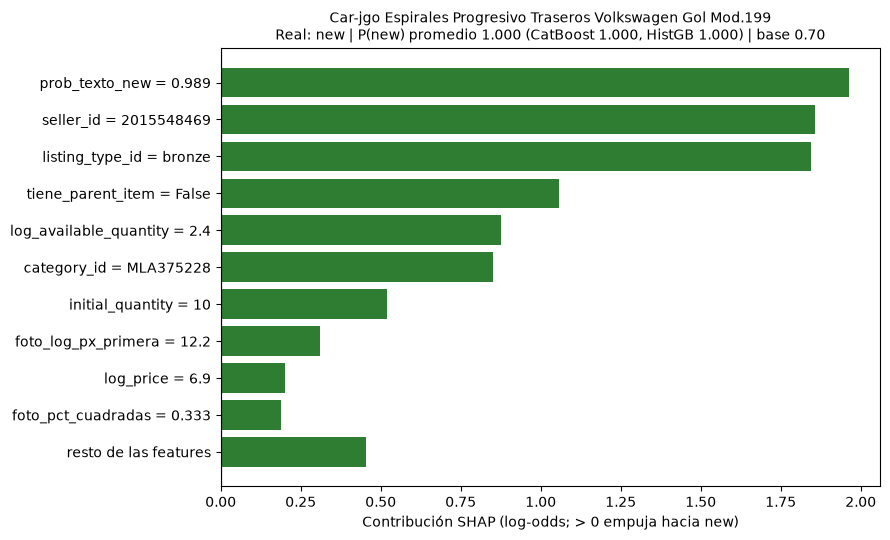

[error] Bisel Marco Frontal De Carcasa Lg G Pro E980 E985 F240 | real used | P(new) 0.999 | duración 60.00000 días | vendedor con 58 publicaciones en train


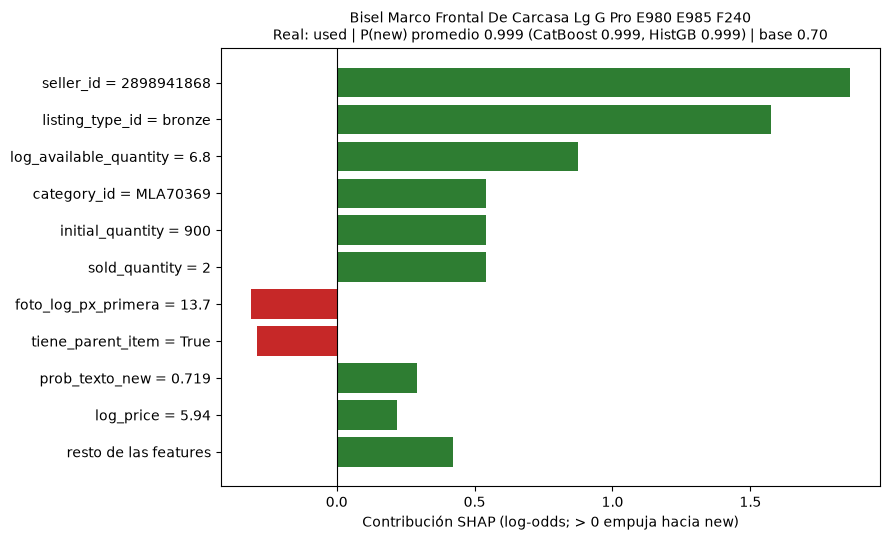

[duracion] Partido Laborista: Estado Y Sindicatos Elena Susana Pont | real used | P(new) 0.001 | duración 60.00009 días | vendedor con 31 publicaciones en train


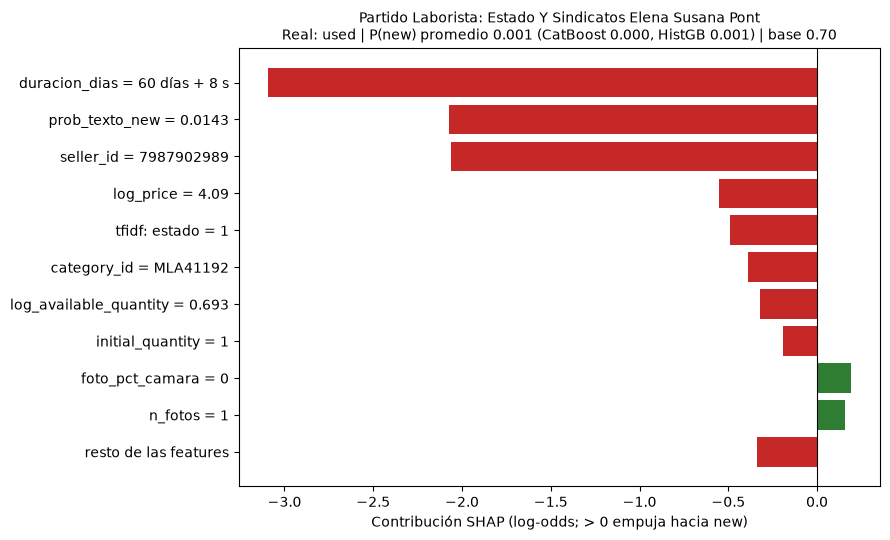

In [5]:
acierto = (prob_final >= 0.5) == y_val
duracion = X_val["duracion_dias"].to_numpy()
candidatos = {
    "acierto": np.where(acierto & (y_val == 1) & (X_val["es_tienda_oficial"].to_numpy() == 0))[0],
    "error": np.where(~acierto)[0],
    "duracion": np.where(acierto & (duracion > 60) & (duracion <= 60 + 120 / 86400))[0],
}
elegidos = {
    "acierto": candidatos["acierto"][np.argmax(prob_final[candidatos["acierto"]])],
    "error": candidatos["error"][np.argmax(np.abs(prob_final[candidatos["error"]] - 0.5))],
    "duracion": candidatos["duracion"][np.argmin(prob_final[candidatos["duracion"]])],
}


def valor_legible(nombre, valor):
    if nombre == "duracion_dias":
        dias = float(valor)
        segundos = round((dias - int(dias)) * 86400)
        return f"{int(dias)} días + {segundos} s" if segundos else f"{int(dias)} días exactos"
    if isinstance(valor, (float, np.floating)):
        return f"{valor:.3g}"
    return str(valor)[:25]


def grafico_waterfall(i, nombre_archivo, titulo):
    valores = shap_cat[i]
    orden = np.argsort(-np.abs(valores))[:10]
    resto = valores.sum() - valores[orden].sum()
    etiquetas = [f"{nombres_cat[j]} = {valor_legible(nombres_cat[j], Xc_val[i, j])}" for j in orden] + ["resto de las features"]
    contribuciones = list(valores[orden]) + [resto]
    fig, ax = plt.subplots(figsize=(9, 5.5))
    colores = ["#2e7d32" if v > 0 else "#c62828" for v in contribuciones]
    ax.barh(etiquetas[::-1], contribuciones[::-1], color=colores[::-1])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("Contribución SHAP (log-odds; > 0 empuja hacia new)")
    ax.set_title(titulo, fontsize=10)
    plt.tight_layout()
    plt.savefig(f"figuras/{nombre_archivo}", dpi=150)
    plt.show()


for clave, archivo in [("acierto", "shap_ejemplo_acierto.png"), ("error", "shap_ejemplo_error.png"),
                       ("duracion", "shap_ejemplo_duracion.png")]:
    i = elegidos[clave]
    fila = X_val.iloc[i]
    titulo = (f"{fila['title'][:60]}\nReal: {'new' if y_val[i] else 'used'} | P(new) promedio {prob_final[i]:.3f} "
              f"(CatBoost {prob_cat[i]:.3f}, HistGB {prob_hgb[i]:.3f}) | base {1 / (1 + np.exp(-valor_base_cat)):.2f}")
    print(f"[{clave}] {fila['title']} | real {'new' if y_val[i] else 'used'} | P(new) {prob_final[i]:.3f} | "
          f"duración {fila['duracion_dias']:.5f} días | vendedor con {int((train.iloc[entrena]['seller_id'] == fila['seller_id']).sum())} publicaciones en train")
    grafico_waterfall(i, archivo, titulo)

## Conclusión (para la presentación)

Fold 1 (modelos entrenados con los folds 2–5): CatBoost 0,9415, HistGB 0,9428, **promedio 0,9431**.

**Importancia global, CatBoost** (`figuras/shap_global_catboost.png`):
1. **`listing_type_id`** (tipo de publicación: free/bronze/silver/gold…);
2. **`prob_texto_new`** (el modelo de texto sobre título + garantía);
3. **`seller_id`** (quién vende);
4. luego cantidades disponibles, categoría, si es una republicación (`tiene_parent_item`), el TF-IDF del título, precio y las features de **fotos**.

`duracion_dias` aparece en el puesto 13: afecta a pocas filas, pero en esas pesa muchísimo. Palabras del título con más peso: *nuevo, estado, nueva, sin, impecable, hp*.

**Importancia global, HistGB** (`figuras/shap_global_histgb.png`):
1. **`prob_texto_new`**;
2. `listing_type_id = free`;
3. el *target encoding* de **vendedor × tipo de publicación** (`c_seller_lt`);
4. luego TF-IDF, cantidades, `tiene_parent_item` y varias combinaciones del vendedor.

Las combinaciones vendedor × algo (`c_seller_lt`, `c_seller_price`, `c_seller_bm`) son justamente lo que le dio al HistGB el salto de la ronda P7.

**Los dos modelos coinciden en lo esencial:** tipo de publicación, texto y vendedor explican la mayor parte. CatBoost los usa crudos; el HistGB, a través de combinaciones.

**Ejemplos individuales (SHAP de CatBoost):**
- **Acierto** (`figuras/shap_ejemplo_acierto.png`): "Car-jgo Espirales Progresivo Traseros Volkswagen Gol", `new`, P(new) = 1,000. Vendedor con 405 publicaciones en train (un comercio de repuestos).
- **Error** (`figuras/shap_ejemplo_error.png`): "Bisel Marco Frontal De Carcasa Lg G Pro…", real `used`, P(new) = 0,999. Todo dice "comercio de repuestos nuevos": vendedor con 58 publicaciones, `bronze`, 900 unidades iniciales, mucho stock. Es el tipo de error "seguro" de `08_errores`: probablemente una etiqueta discutible del vendedor, imposible de corregir con estas features.
- **Duración** (`figuras/shap_ejemplo_duracion.png`): "Partido Laborista: Estado Y Sindicatos…", `used`, P(new) = 0,001. La feature que más empuja hacia `used` es **`duracion_dias` = 60,00009** (60 días + 8 segundos), aún más que el texto y el vendedor. *Nota:* en el gráfico guardado la etiqueta dice "60" por un redondeo a 3 cifras; el código ya está corregido para mostrar 5 decimales en la próxima corrida.

**SHAP** no está en el material: reparte cada predicción entre las features, de modo que valor base + suma de contribuciones = predicción (en log-odds); se verificó que cierra exacto para CatBoost.

**Tiempo:** 121 minutos, por la poca memoria libre de la máquina (con la máquina libre debería ser mucho menos).